In [4]:
from models.netload_reader.get_victron_data import fetch_victron_data, fetch_victron_soc
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


In [5]:
# Messungen laden
SIM_START = pd.Timestamp('2026-04-10 19:30', tz='Europe/Vienna')
SIM_END = pd.Timestamp('2026-04-17 19:30', tz='Europe/Vienna')
SIM_TZ = 'Europe/Vienna'
df_victron = fetch_victron_data(
    start=SIM_START,
    end=SIM_END,
    timezone=SIM_TZ)
P_grid_measured = df_victron['P_grid'][1:]

soc_series = fetch_victron_soc(start=SIM_START, end=SIM_END, timezone=SIM_TZ)

# MPC-Ergebnisse laden
df_mpc = pd.read_parquet('../data/mp_controller_homebattery/mpc_results_20260410_193659.parquet')
P_grid_set = df_mpc.groupby('mpc_time')['set_netload_kw'].first()
P_grid_set = P_grid_set.resample('15min').mean()
P_grid_set = P_grid_set[SIM_START:SIM_END]
P_grid_set = P_grid_set * 1000  # kW → W


Fetching VRM data from 2026-04-10 19:30:00+02:00 to 2026-04-17 19:15:00+02:00 ...


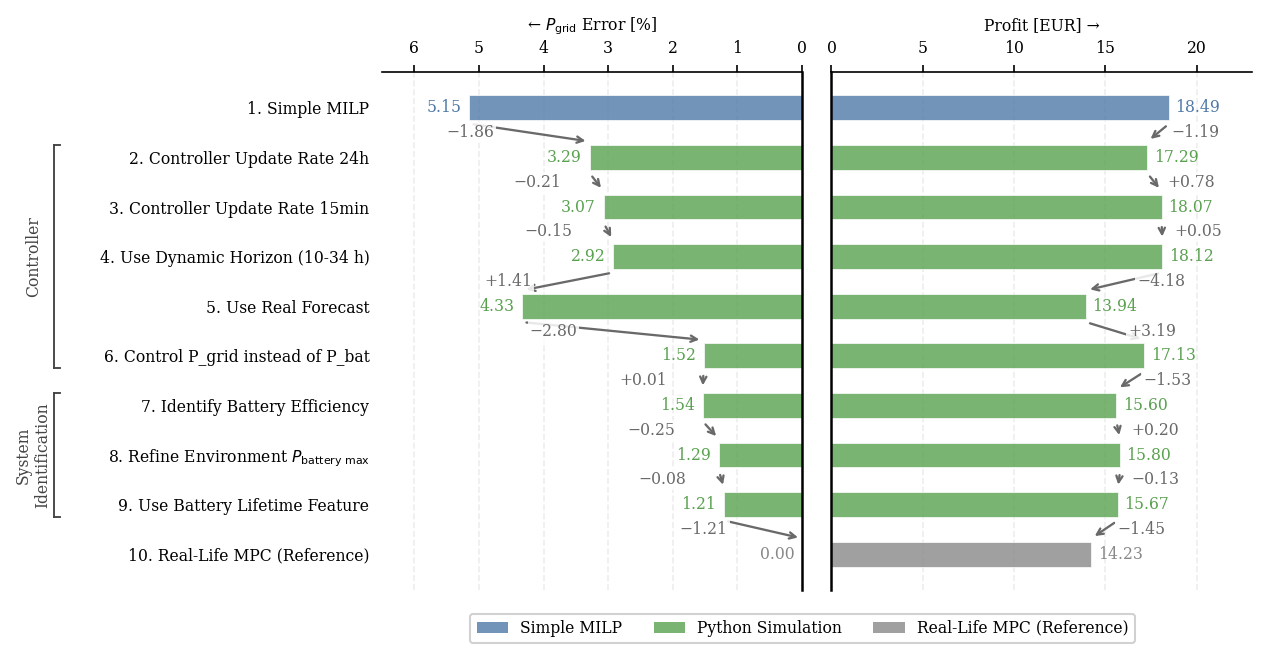

In [6]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
import matplotlib.lines as mlines
from matplotlib.transforms import blended_transform_factory

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

text_size = 7.5

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': text_size,
    'axes.labelsize': text_size,
    'xtick.labelsize': text_size,
    'ytick.labelsize': text_size,
    'legend.fontsize': text_size,
    'figure.dpi': 150,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

# ── Data ───────────────────────────────────────────────────────────────────────
labels = [
    '1. Simple MILP',
    '2. Controller Update Rate 24h',
    '3. Controller Update Rate 15min',
    '4. Use Dynamic Horizon (10-34 h)',
    '5. Use Real Forecast',
    '6. Control P_grid instead of P_bat',
    '7. Identify Battery Efficiency',
    '8. Refine Environment $P_{\\mathrm{battery~max}}$',
    '9. Use Battery Lifetime Feature',
    '10. Real-Life MPC (Reference)',
]
profits = [18.4875, 17.293, 18.0726, 18.1183, 13.9368, 17.1302, 15.6013	, 15.8018, 15.6747, 14.2254]
nmae    = [ 5.1465, 3.2862, 3.0713,  2.9225, 4.32879, 1.5248,  1.538,  1.2859,  1.2055,  0.0]


groups = [0, 1, 1, 1, 1, 1, 1, 1, 1, 2]
GC = ['#4e79a7', '#59a14f', '#888888']   # blue / green / gray
bar_colors = [GC[g] for g in groups]

real_mpc = profits[-1]
n = len(labels)
y = np.arange(n)
bar_h = 0.5

min_p = 0.0   # profit axis [EUR]
max_p = 23.0   # profit axis [EUR]
max_n = 6.5    # nMAE axis [%]

# ── Two subplots, shared y ─────────────────────────────────────────────────────
fig_width_inch = 190 / 25.4
fig_height_inch = fig_width_inch * 0.6
fig, (ax_nmae, ax_profit) = plt.subplots(
    1, 2, figsize=(fig_width_inch, fig_height_inch), sharey=True,
    gridspec_kw={'wspace': 0.07, 'width_ratios': [1, 1]},
)
ax_nmae.invert_yaxis()   # propagates to ax_profit via sharey

# ── LEFT: nMAE (right-aligned — bars grow leftward from divider) ──────────────
ax_nmae.set_xlim(max_n, 0)

for yi, nv, c in zip(y, nmae, bar_colors):
    if not np.isnan(nv):
        ax_nmae.barh(yi, nv, color=c, alpha=0.8, height=bar_h,
                     edgecolor='white', linewidth=0.4, zorder=3)
        ax_nmae.text(nv + 0.12, yi, f'{nv:.2f}', va='center', ha='right',
                     fontsize=text_size, color=c, zorder=6, clip_on=False)
    else:
        ax_nmae.text(0.12, yi, '— reference —', va='center', fontsize=text_size,
                     color='gray', style='italic', zorder=6)

ax_nmae.set_xticks(list(range(0, int(max_n) + 1, 1)))
ax_nmae.xaxis.set_ticks_position('top')
ax_nmae.xaxis.set_label_position('top')
ax_nmae.set_xlabel('← $P_{\\mathrm{grid}}$ Error [%]', labelpad=5)
ax_nmae.tick_params(axis='x', which='both', top=True, bottom=False)

ax_nmae.set_yticks(y)
ax_nmae.set_yticklabels(labels, fontsize=text_size)
ax_nmae.tick_params(axis='y', which='both', length=0, pad=6)

ax_nmae.spines['left'].set_visible(False)
ax_nmae.spines['bottom'].set_visible(False)
ax_nmae.spines['top'].set_visible(True)
ax_nmae.spines['right'].set_visible(True)
ax_nmae.spines['right'].set_linewidth(1.2)
ax_nmae.spines['right'].set_zorder(25)
ax_nmae.spines['top'].set_zorder(25)

ax_nmae.grid(True, axis='x', alpha=0.22, ls='--', zorder=0)
ax_nmae.set_axisbelow(True)

# ── RIGHT: Profit (left-aligned — bars grow rightward from divider) ───────────
ax_profit.set_xlim(0, max_p)

ax_profit.barh(y, profits, color=bar_colors, alpha=0.8, height=bar_h,
               edgecolor='white', linewidth=0.4, zorder=3)

for yi, p, c in zip(y, profits, bar_colors):
    ax_profit.text(p + 0.35, yi, f'{p:.2f}', va='center', ha='left',
                   fontsize=text_size, color=c, zorder=6, clip_on=False)

ticks_p = np.arange(0, 26, 5)
ax_profit.set_xticks(ticks_p)
ax_profit.set_xticklabels([str(int(t)) for t in ticks_p])
ax_profit.xaxis.set_ticks_position('top')
ax_profit.xaxis.set_label_position('top')
ax_profit.set_xlabel('Profit [EUR] →', labelpad=5)
ax_profit.tick_params(axis='x', which='both', top=True, bottom=False)

ax_profit.tick_params(axis='y', which='both', length=0, labelleft=False, pad=6)

ax_profit.spines['left'].set_visible(True)
ax_profit.spines['left'].set_linewidth(1.2)
ax_profit.spines['left'].set_zorder(25)
ax_profit.spines['bottom'].set_visible(False)
ax_profit.spines['top'].set_visible(True)
ax_profit.spines['top'].set_zorder(25)
ax_profit.spines['right'].set_visible(False)

ax_profit.grid(True, axis='x', alpha=0.22, ls='--', zorder=0)
ax_profit.set_axisbelow(True)
ax_profit.set_xlim(min_p, max_p)

# ── Arrows between consecutive bar maxima ──────────────────────────────────────
arrow_kw = dict(arrowstyle='->', color='dimgray', lw=1.1,
                connectionstyle='arc3,rad=0.0')
gap = 0.32

for i in range(n - 1):
    x0, x1 = profits[i], profits[i + 1]
    ax_profit.annotate('', xy=(x1, i + 1 - gap), xytext=(x0, i + gap),
                       arrowprops=dict(**arrow_kw), zorder=12)
    delta = profits[i] - profits[i + 1]
    sign = '−' if delta > 0 else '+'
    ax_profit.text(
        (x0 + x1) / 2 + 0.7, i + 0.5,
        f'{sign}{abs(delta):.2f}',
        va='center', ha='left', fontsize=text_size, color='dimgray',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1),
        zorder=13,
    )

for i in range(n - 1):
    nv0, nv1 = nmae[i], nmae[i + 1]
    if np.isnan(nv0) or np.isnan(nv1):
        continue
    ax_nmae.annotate('', xy=(nv1, i + 1 - gap), xytext=(nv0, i + gap),
                     arrowprops=dict(**arrow_kw), zorder=12)
    delta = nv0 - nv1
    sign = '−' if delta > 0 else '+'
    ax_nmae.text(
        (nv0 + nv1) / 2 + 0.55, i + 0.5,
        f'{sign}{abs(delta):.2f}',
        va='center', ha='right', fontsize=text_size, color='dimgray',
        bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1),
        zorder=13,
    )

# ── Group bracket annotations (left of y-axis) ────────────────────────────────
def add_left_bracket(ax, y0, y1, label, x_bar=-0.78, x_label=-0.83,
                     tick=0.014, color='#444444', fs=text_size):
    """Vertical bracket with end-ticks and rotated label, left of the axes."""
    trans = blended_transform_factory(ax.transAxes, ax.transData)
    mid = (y0 + y1) / 2
    lw = 0.9
    ax.plot([x_bar, x_bar], [y0, y1], transform=trans,
            color=color, lw=lw, clip_on=False, zorder=20)
    for y_end in [y0, y1]:
        ax.plot([x_bar, x_bar + tick], [y_end, y_end], transform=trans,
                color=color, lw=lw, clip_on=False, zorder=20)
    ax.text(x_label, mid, label, transform=trans,
            ha='center', va='center', fontsize=fs,
            rotation=90, color=color, clip_on=False)

add_left_bracket(ax_nmae, 1 - bar_h / 2, 5 + bar_h / 2,
                 'Controller')
add_left_bracket(ax_nmae, 6 - bar_h / 2, 8 + bar_h / 2,
                 'System\nIdentification')

# ── Legend ─────────────────────────────────────────────────────────────────────
legend_elements = [
    Patch(facecolor=GC[0], alpha=0.8, label='Simple MILP'),
    Patch(facecolor=GC[1], alpha=0.8, label='Python Simulation'),
    Patch(facecolor=GC[2], alpha=0.8, label='Real-Life MPC (Reference)'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4,
           framealpha=0.9, bbox_to_anchor=(0.5, 0.02))

plt.savefig('simulation_gap.pdf', bbox_inches='tight')
plt.show()


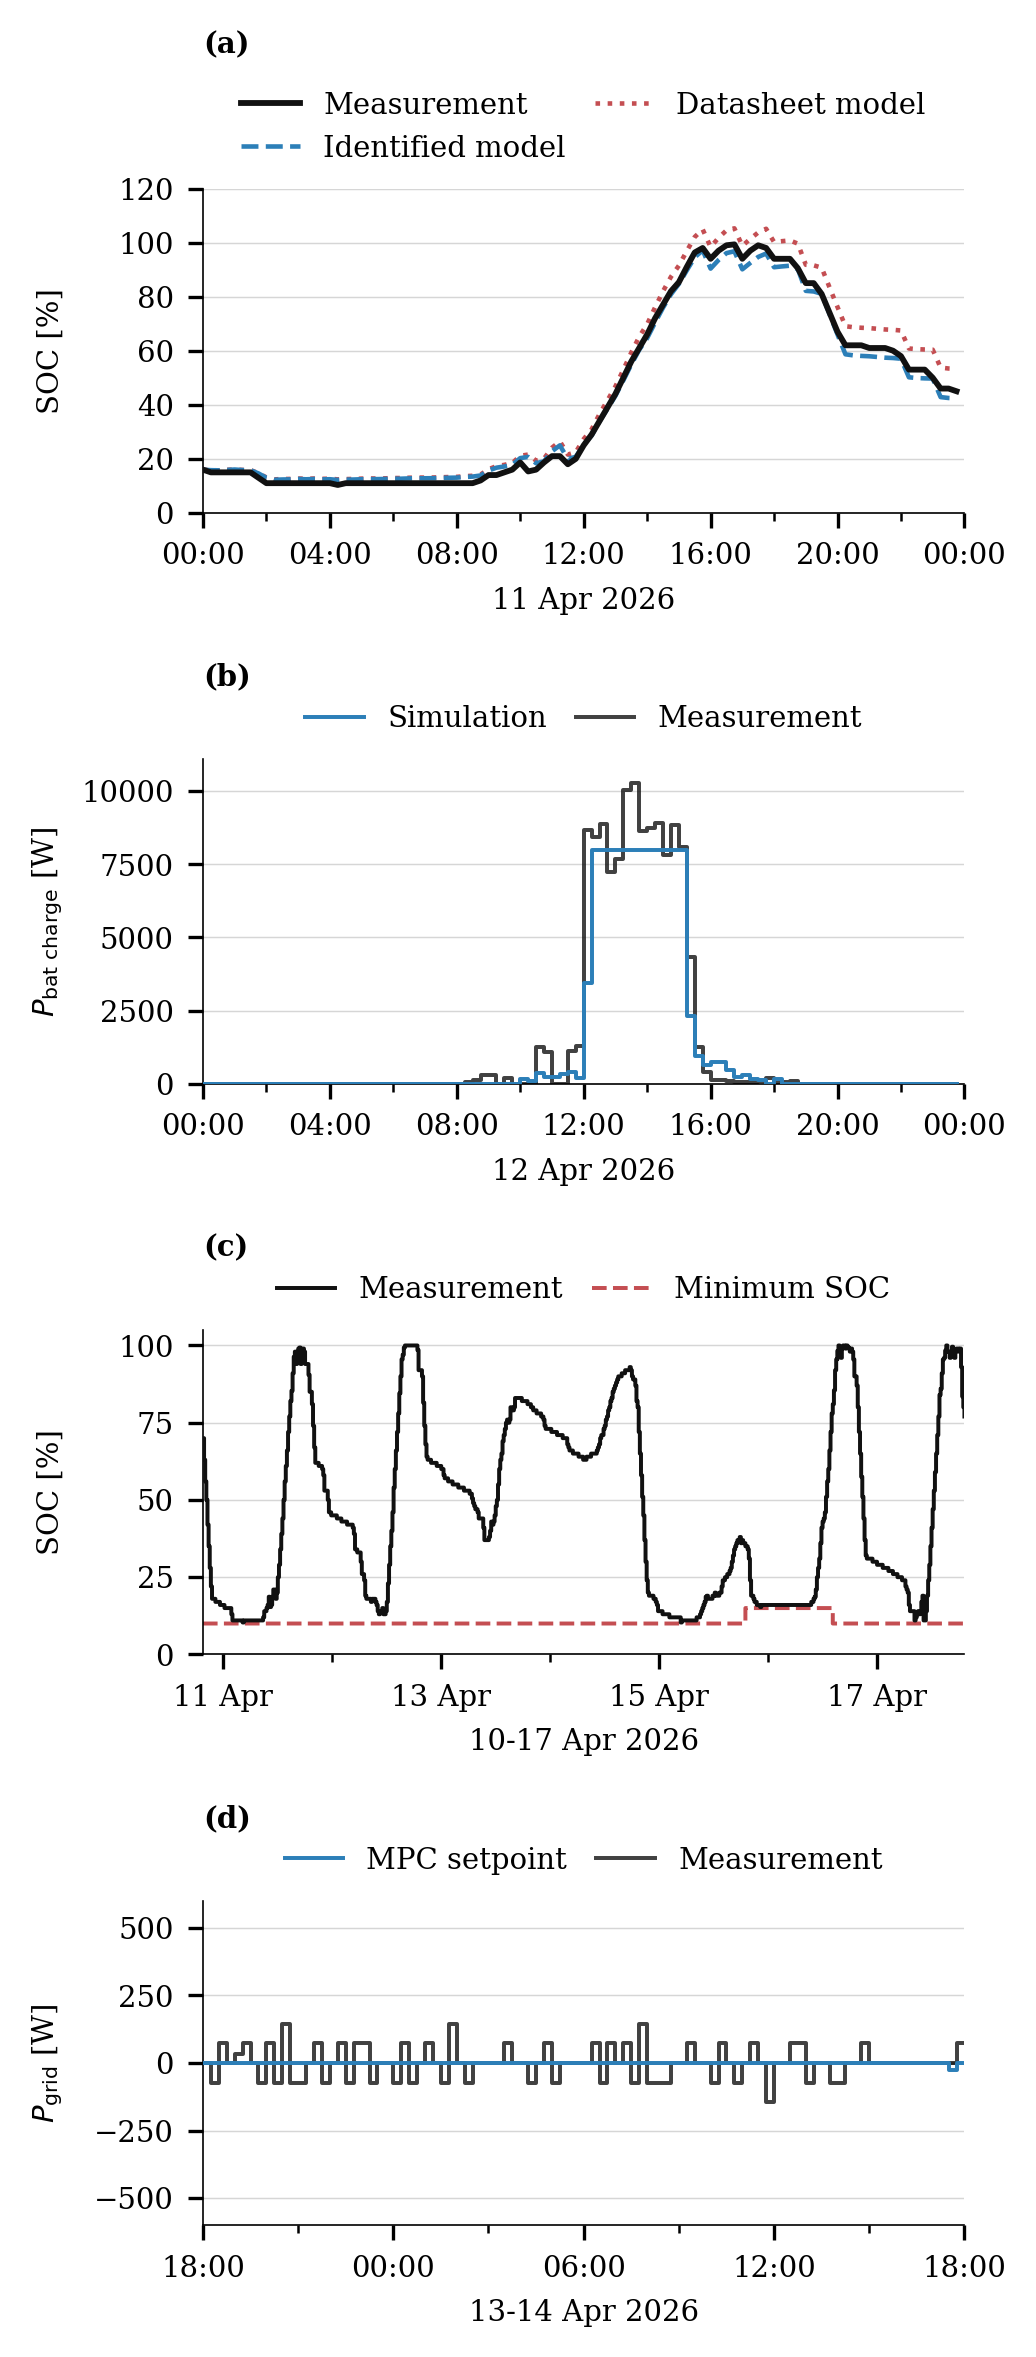

In [7]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.ticker import MultipleLocator

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

text_size = 7.0

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': text_size,
    'axes.labelsize': text_size,
    'xtick.labelsize': text_size,
    'ytick.labelsize': text_size,
    'legend.fontsize': text_size,
    'figure.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

colors = {
    'measurement': '#111111',
    'model': '#2c7fb8',
    'reference': '#c44e52',
    'secondary': '#6f6f6f',
    'grid': '#d6d6d6',
}

def style_axis(ax):
    ax.grid(False)
    ax.xaxis.grid(False, which='both')
    ax.yaxis.grid(True, which='major', color=colors['grid'], linewidth=0.35)
    ax.set_axisbelow(True)
    ax.margins(x=0)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#000000')
        ax.spines[spine].set_linewidth(0.4)

def add_panel_label(ax, label, y=1.21):
    ax.text(
        0.0, y, label,
        transform=ax.transAxes,
        ha='left', va='bottom',
        fontsize=text_size,
        fontweight='bold',
    )

def place_legend(ax, ncol):
    ax.legend(
        loc='lower center',
        bbox_to_anchor=(0.5, 1.0),
        ncol=ncol,
        frameon=False,
        handlelength=2.0,
        columnspacing=1.0,
    )

day_start = pd.Timestamp('2026-04-11 00:00', tz=SIM_TZ)
day_end = pd.Timestamp('2026-04-12 00:00', tz=SIM_TZ)
start_soc_percent = 16.0
E_bat_max_kWh = 30.72
P_bat_meas = df_victron['P_bat']

soc_real_day = soc_series[(soc_series.index >= day_start) & (soc_series.index < day_end)]
P_bat_day_kw = (P_bat_meas / 1000)[(P_bat_meas.index >= day_start) & (P_bat_meas.index < day_end)]

assert not soc_real_day.empty, 'Keine SOC-Messdaten fuer den 11. April gefunden.'
assert soc_real_day.index.equals(P_bat_day_kw.index), 'SOC- und P_bat-Indizes fuer den 11. April stimmen nicht ueberein.'

def batterymodel(soc_prev, P_bat_kw, eta_c, eta_d):
    if P_bat_kw > 0:
        dE = P_bat_kw * 0.25 * eta_c
    else:
        dE = P_bat_kw * 0.25 / eta_d
    return soc_prev + dE

def simulate_soc_percent(power_series_kw, eta_c, eta_d, start_soc_percent, capacity_kwh):
    soc_values_kwh = [start_soc_percent / 100 * capacity_kwh]
    soc_index = [power_series_kw.index[0]]
    for timestamp, power_kw in power_series_kw.iloc[:-1].items():
        soc_next_kwh = batterymodel(soc_values_kwh[-1], power_kw, eta_c, eta_d)
        soc_values_kwh.append(soc_next_kwh)
        next_idx = power_series_kw.index.get_loc(timestamp) + 1
        soc_index.append(power_series_kw.index[next_idx])
    return pd.Series(
        np.array(soc_values_kwh) / capacity_kwh * 100,
        index=soc_index,
    )

soc_fit_day = simulate_soc_percent(
    P_bat_day_kw,
    eta_c=0.867,
    eta_d=0.906,
    start_soc_percent=start_soc_percent,
    capacity_kwh=E_bat_max_kWh,
)

eta_paper = np.sqrt(0.95) * 0.96
soc_paper_day = simulate_soc_percent(
    P_bat_day_kw,
    eta_c=eta_paper,
    eta_d=eta_paper,
    start_soc_percent=start_soc_percent,
    capacity_kwh=E_bat_max_kWh,
)

plot_start = pd.Timestamp('2026-04-13 18:00', tz=SIM_TZ)
plot_end = pd.Timestamp('2026-04-14 18:00', tz=SIM_TZ)
grid_measured = P_grid_measured[plot_start:plot_end]
grid_setpoint = P_grid_set[plot_start:plot_end]

output_dir = Path('../data/output/home_bess_simulation/mp_control')
chosen_parquet = output_dir / '20260430_0814.parquet'
if chosen_parquet is None:
    chosen_parquet = sorted(output_dir.glob('*.parquet'))[-1]
df_sim = pd.read_parquet(chosen_parquet)
P_bat_sim = df_sim[('Battery', 'outputs', 'P_bat')]

charge_start = pd.Timestamp('2026-04-12 00:00', tz=SIM_TZ)
charge_end = pd.Timestamp('2026-04-13 00:00', tz=SIM_TZ)
p_bat_meas_day = P_bat_meas[(P_bat_meas.index >= charge_start) & (P_bat_meas.index < charge_end)]
p_bat_sim_day = P_bat_sim[(P_bat_sim.index >= charge_start) & (P_bat_sim.index < charge_end)]
p_bat_meas_charge = p_bat_meas_day.clip(lower=0)
p_bat_sim_charge = p_bat_sim_day.clip(lower=0)
charge_plot_max = pd.concat([p_bat_meas_charge, p_bat_sim_charge]).max()
charge_plot_max = 1.08 * charge_plot_max if pd.notna(charge_plot_max) else 1000

soc_plot_start = soc_series.index.min()
soc_plot_end = soc_series.index.max()
soc_min_series = pd.Series(10.0, index=soc_series.index)
soc_min_start = pd.Timestamp('2026-04-15 19:00', tz=SIM_TZ)
soc_min_end = pd.Timestamp('2026-04-16 14:00', tz=SIM_TZ)
soc_min_series.loc[(soc_min_series.index >= soc_min_start) & (soc_min_series.index <= soc_min_end)] = 15.0

fig_width_inch = 88 / 25.4
fig_height_inch = fig_width_inch * 2.3
fig, axes = plt.subplots(4, 1, figsize=(fig_width_inch, fig_height_inch))

ax = axes[0]
ax.plot(
    soc_real_day.index,
    soc_real_day.values,
    color=colors['measurement'],
    linewidth=1.4,
    label='Measurement',
    zorder=3,
)
ax.plot(
    soc_fit_day.index,
    soc_fit_day.values,
    color=colors['model'],
    linewidth=1.1,
    linestyle='--',
    label='Identified model',
    zorder=2,
)
ax.plot(
    soc_paper_day.index,
    soc_paper_day.values,
    color=colors['reference'],
    linewidth=1.1,
    linestyle=':',
    label='Datasheet model',
    zorder=1,
)
ax.set_ylabel('SOC [%]')
ax.set_xlim(day_start, day_end)
ax.set_ylim(0, 120)
ax.yaxis.set_major_locator(MultipleLocator(20))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=4, tz=day_start.tz))
ax.xaxis.set_minor_locator(mdates.HourLocator(interval=2, tz=day_start.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=day_start.tz))
ax.set_xlabel('11 Apr 2026')
style_axis(ax)
add_panel_label(ax, '(a)', y=1.4)
place_legend(ax, 2)

ax = axes[1]
ax.step(
    p_bat_sim_charge.index,
    p_bat_sim_charge.values,
    where='post',
    color=colors['model'],
    lw=0.95,
    label='Simulation',
    zorder=3,
)
ax.step(
    p_bat_meas_charge.index,
    p_bat_meas_charge.values,
    where='post',
    color=colors['measurement'],
    lw=0.95,
    alpha=0.8,
    label='Measurement',
    zorder=2,
)
ax.set_xlim(charge_start, charge_end)
ax.set_ylim(0, charge_plot_max)
ax.set_ylabel('$P_{\\mathrm{bat~charge}}$ [W]')
ax.set_xlabel('12 Apr 2026')
ax.xaxis.set_major_locator(mdates.HourLocator(interval=4, tz=charge_start.tz))
ax.xaxis.set_minor_locator(mdates.HourLocator(interval=2, tz=charge_start.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=charge_start.tz))
style_axis(ax)
add_panel_label(ax, '(b)')
place_legend(ax, 2)

ax = axes[2]
ax.step(
    soc_series.index,
    soc_series.values,
    where='post',
    color=colors['measurement'],
    lw=0.95,
    label='Measurement',
    zorder=3,
)
ax.step(
    soc_min_series.index,
    soc_min_series.values,
    where='post',
    color=colors['reference'],
    lw=0.95,
    linestyle='--',
    label='Minimum SOC',
    zorder=2,
)
ax.set_xlim(soc_plot_start, soc_plot_end)
ax.set_ylim(0, 105)
ax.set_ylabel('SOC [%]')
ax.set_xlabel('10-17 Apr 2026')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2, tz=soc_plot_start.tz))
ax.xaxis.set_minor_locator(mdates.DayLocator(interval=1, tz=soc_plot_start.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b', tz=soc_plot_start.tz))
style_axis(ax)
add_panel_label(ax, '(c)')
place_legend(ax, 2)

ax = axes[3]
ax.step(
    grid_setpoint.index,
    grid_setpoint.values,
    where='post',
    color=colors['model'],
    lw=0.95,
    label='MPC setpoint',
    zorder=3,
)
ax.step(
    grid_measured.index,
    grid_measured.values,
    where='post',
    color=colors['measurement'],
    lw=0.95,
    alpha=0.8,
    label='Measurement',
    zorder=2,
)
ax.axhline(0, color=colors['secondary'], lw=0.6, zorder=1)
ax.set_ylabel('$P_{\\mathrm{grid}}$ [W]')
ax.set_xlim(plot_start, plot_end)
ax.set_ylim(-600, 600)
ax.set_xlabel('13-14 Apr 2026')
ax.xaxis.set_major_locator(mdates.HourLocator(interval=6, tz=plot_start.tz))
ax.xaxis.set_minor_locator(mdates.HourLocator(interval=3, tz=plot_start.tz))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=plot_start.tz))
style_axis(ax)
add_panel_label(ax, '(d)')
place_legend(ax, 2)

fig.align_ylabels(axes)
fig.tight_layout()
plt.savefig('system_identification.pdf', bbox_inches='tight', transparent=True)
plt.show()


Maximaler Unterschied zwischen gemessenem und simuliertem SOC: 7.59 %-Punkte
Mean Absolute Error (MAE) zwischen gemessenem und simuliertem SOC: 1.65 %-Punkte
nMAE zwischen Forecast und gemessener Net Load (bezogen auf max-min): 5.30%
Fetching VRM data from 2026-04-03 19:30:00+02:00 to 2026-04-17 19:15:00+02:00 ...


nMAE zwischen Persistence (1d Lag) und gemessener Net Load (bezogen auf max-min): 8.64%


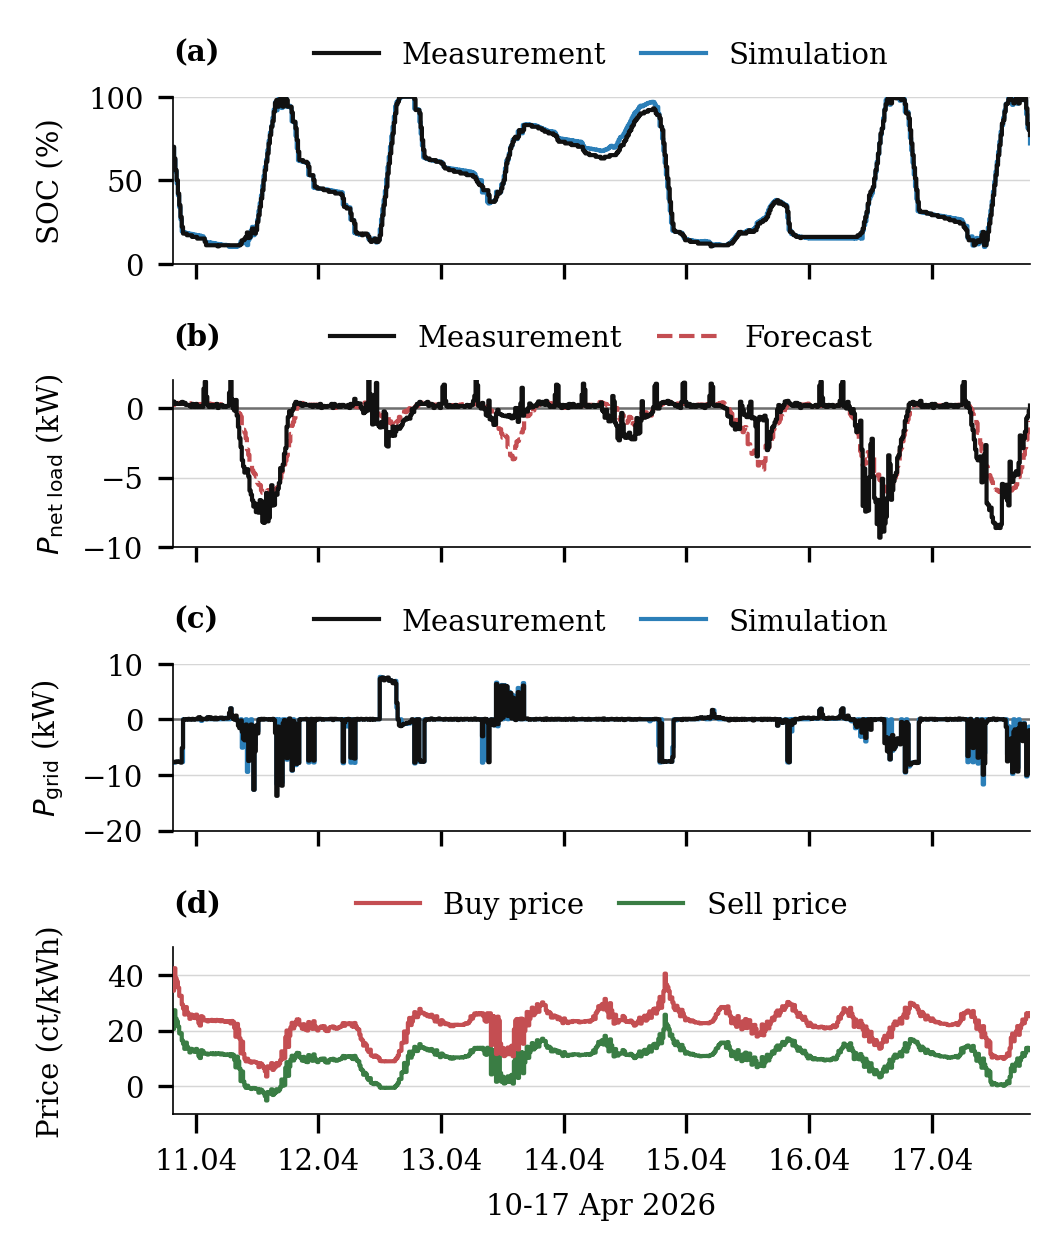

In [8]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
from pathlib import Path
from matplotlib.ticker import MultipleLocator

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sim_parquet = Path('../data/output/home_bess_simulation/mp_control/20260503_0949.parquet')
df_sim_validation = pd.read_parquet(sim_parquet)

soc_sim_validation = df_sim_validation[('Battery', 'outputs', 'SOC_percent')]
p_grid_sim_validation = df_sim_validation[('Smart Meter', 'outputs', 'P_grid')]
price_buy_validation = df_sim_validation[('Electric Utility Company', 'outputs', 'price_buy')]
price_sell_validation = df_sim_validation[('Electric Utility Company', 'outputs', 'price_sell')]

forecast_df = df_mpc.groupby('timestamp').last()
netload_forecast = forecast_df['netload_forecast_kw'] * 1000
netload_measured = df_victron['net_load']

plot_start = max(
    soc_series.index.min(),
    soc_sim_validation.index.min(),
    netload_forecast.index.min(),
    netload_measured.index.min(),
    p_grid_sim_validation.index.min(),
    price_buy_validation.index.min(),
)
plot_end = min(
    soc_series.index.max(),
    soc_sim_validation.index.max(),
    netload_forecast.index.max(),
    netload_measured.index.max(),
    p_grid_sim_validation.index.max(),
    price_buy_validation.index.max(),
    price_sell_validation.index.max(),
)

soc_measured_plot = soc_series.loc[plot_start:plot_end]
soc_sim_plot = soc_sim_validation.loc[plot_start:plot_end]
netload_forecast_plot = netload_forecast.loc[plot_start:plot_end]
netload_measured_plot = netload_measured.loc[plot_start:plot_end]
p_grid_measured_plot = P_grid_measured.loc[plot_start:plot_end]
p_grid_sim_plot = p_grid_sim_validation.loc[plot_start:plot_end]
price_buy_plot = price_buy_validation.loc[plot_start:plot_end] * 100
price_sell_plot = price_sell_validation.loc[plot_start:plot_end] * 100

soc_compare = pd.concat(
    [
        soc_measured_plot.rename('measured'),
        soc_sim_plot.rename('simulated'),
    ],
    axis=1,
).dropna()
max_soc_diff = (soc_compare['measured'] - soc_compare['simulated']).abs().max()
print(f'Maximaler Unterschied zwischen gemessenem und simuliertem SOC: {max_soc_diff:.2f} %-Punkte')
mae_soc = (soc_compare['measured'] - soc_compare['simulated']).abs().mean()
print(f'Mean Absolute Error (MAE) zwischen gemessenem und simuliertem SOC: {mae_soc:.2f} %-Punkte')

netload_compare = pd.concat(
    [
        netload_measured_plot.rename('measured'),
        netload_forecast_plot.rename('forecast'),
    ],
    axis=1,
).dropna()
mae_netload_forecast = (netload_compare['measured'] - netload_compare['forecast']).abs().mean()
netload_reference = netload_compare['measured'].max() - netload_compare['measured'].min()
nmae_netload_forecast = 100 * mae_netload_forecast / netload_reference
print(
    f'nMAE zwischen Forecast und gemessener Net Load (bezogen auf max-min): '
    f'{nmae_netload_forecast:.2f}%'
 )

# Persistence baseline: 1d lag (vorherige Woche als Forecast)
netload_measured_incl_lag = fetch_victron_data(
    start=SIM_START - pd.Timedelta(days=7),
    end=SIM_END,
    timezone=SIM_TZ)['P_grid'][1:]
netload_persistence = netload_measured_incl_lag.shift(1 * 24 * 4)  # 1 Tage * 24h * 4 15min-Intervalle
mae_persistence = (netload_persistence - netload_compare['forecast']).dropna().abs().mean()
nmae_persistence = 100 * mae_persistence / (netload_persistence.max() - netload_persistence.min())
print(
    f'nMAE zwischen Persistence (1d Lag) und gemessener Net Load (bezogen auf max-min): '
    f'{nmae_persistence:.2f}%'
 )

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 7.0,
    'axes.labelsize': 7.0,
    'xtick.labelsize': 7.0,
    'ytick.labelsize': 7.0,
    'legend.fontsize': 7.0,
    'figure.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

colors = {
    'measurement': '#111111',
    'simulation': '#2c7fb8',
    'forecast': '#c44e52',
    'buy': '#c44e52',
    'sell': '#3a7d44',
    'grid': '#d6d6d6',
    'baseline': '#6f6f6f',
}

def style_axis(ax, add_y_grid=True):
    ax.grid(False)
    ax.xaxis.grid(False, which='both')
    if add_y_grid:
        ax.yaxis.grid(True, which='major', color=colors['grid'], linewidth=0.35)
    ax.set_axisbelow(True)
    ax.margins(x=0)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#000000')
        ax.spines[spine].set_linewidth(0.4)

def add_panel_label(ax, label):
    ax.text(
        0.0, 1.18, label,
        transform=ax.transAxes,
        ha='left', va='bottom',
        fontsize=7.0,
        fontweight='bold',
    )

def place_legend(ax, ncol):
    ax.legend(
        loc='lower center',
        bbox_to_anchor=(0.5, 1.01),
        ncol=ncol,
        frameon=False,
        handlelength=2.2,
        columnspacing=1.2,
    )

fig_width_inch = 90 / 25.4
fig_height_inch = fig_width_inch * 1.18
fig, axes = plt.subplots(4, 1, figsize=(fig_width_inch, fig_height_inch), sharex=True)

ax = axes[0]
ax.step(
    soc_measured_plot.index,
    soc_measured_plot.values,
    where='post',
    color=colors['measurement'],
    lw=1.0,
    label='Measurement',
    zorder=3,
)
ax.step(
    soc_sim_plot.index,
    soc_sim_plot.values,
    where='post',
    color=colors['simulation'],
    lw=1.0,
    label='Simulation',
    zorder=2,
)
ax.set_ylabel('SOC (%)')
ax.set_ylim(0, 100)
style_axis(ax)
add_panel_label(ax, '(a)')
place_legend(ax, 2)

ax = axes[1]
ax.step(
    netload_measured_plot.index,
    netload_measured_plot.values / 1000,
    where='post',
    color=colors['measurement'],
    lw=1.0,
    label='Measurement',
    zorder=3,
)
ax.step(
    netload_forecast_plot.index,
    netload_forecast_plot.values / 1000,
    where='post',
    color=colors['forecast'],
    lw=1.0,
    linestyle='--',
    label='Forecast',
    zorder=2,
)
ax.axhline(0, color=colors['baseline'], lw=0.6, zorder=1)
ax.set_ylim(-10, 2)
ax.yaxis.set_major_locator(MultipleLocator(5))
ax.set_ylabel('$P_{\\mathrm{net~load}}$ (kW)')
style_axis(ax)
add_panel_label(ax, '(b)')
place_legend(ax, 2)

ax = axes[2]
ax.step(
    p_grid_measured_plot.index,
    p_grid_measured_plot.values / 1000,
    where='post',
    color=colors['measurement'],
    lw=1.0,
    label='Measurement',
    zorder=3,
)
ax.step(
    p_grid_sim_plot.index,
    p_grid_sim_plot.values / 1000,
    where='post',
    color=colors['simulation'],
    lw=1.0,
    label='Simulation',
    zorder=2,
)
ax.axhline(0, color=colors['baseline'], lw=0.6, zorder=1)
ax.set_ylabel('$P_{\\mathrm{grid}}$ (kW)')
ax.set_ylim(-20, 10)
ax.yaxis.set_major_locator(MultipleLocator(10))
style_axis(ax)
add_panel_label(ax, '(c)')
place_legend(ax, 2)

ax = axes[3]
ax.step(
    price_buy_plot.index,
    price_buy_plot.values,
    where='post',
    color=colors['buy'],
    lw=1.0,
    label='Buy price',
    zorder=3,
)
ax.step(
    price_sell_plot.index,
    price_sell_plot.values,
    where='post',
    color=colors['sell'],
    lw=1.0,
    label='Sell price',
    zorder=2,
)
ax.set_ylabel('Price (ct/kWh)')
style_axis(ax)
add_panel_label(ax, '(d)')
ax.set_ylim(-10, 50)
ax.yaxis.set_major_locator(MultipleLocator(20))
place_legend(ax, 2)

major_ticks = [
    pd.Timestamp('2026-04-11 00:00', tz=plot_start.tz),
    pd.Timestamp('2026-04-12 00:00', tz=plot_start.tz),
    pd.Timestamp('2026-04-13 00:00', tz=plot_start.tz),
    pd.Timestamp('2026-04-14 00:00', tz=plot_start.tz),
    pd.Timestamp('2026-04-15 00:00', tz=plot_start.tz),
    pd.Timestamp('2026-04-16 00:00', tz=plot_start.tz),
    pd.Timestamp('2026-04-17 00:00', tz=plot_start.tz),
]
minor_ticks = pd.date_range(
    plot_start.floor('D') + pd.Timedelta(days=1),
    plot_end - pd.Timedelta(days=1),
    freq='D',
    tz=plot_start.tz,
 )
axes[-1].set_xlabel('10-17 Apr 2026')
axes[-1].set_xticks(major_ticks)
axes[-1].set_xticks(minor_ticks, minor=True)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d.%m', tz=plot_start.tz))
axes[-1].tick_params(axis='x', which='major', length=4.5)
axes[-1].tick_params(axis='x', which='minor', length=2.5, labelbottom=False)
axes[-1].set_xlim(plot_start, plot_end)

fig.align_ylabels(axes)
fig.tight_layout()
plt.savefig('home_bess_timeseries.pdf', bbox_inches='tight', transparent=True)
plt.show()
